# Questão 1: Rede MLP para regressão

Nesta questão usamos uma rede Perceptron de Múltiplas Camadas (MLP) em dois problemas de regressão, ou seja, problemas em que a rede precisa prever um número.

- Item a: aproximar a função f(x) = 3 sen(2x) + 2 cos(5x) + 0,5x², com x entre 0 e 10.
- Item b: prever a progressão do diabetes de um paciente a partir de 10 informações clínicas (base Diabetes do scikit-learn).

Nos dois itens separamos os dados em três partes:
- treino: os dados que a rede usa para aprender;
- validação: dados que a rede não usa para aprender, mas que olhamos a cada época para ver se ela está melhorando de verdade;
- teste: dados guardados até o final, usados uma única vez para medir o desempenho.

## Bibliotecas

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

# usa a placa de vídeo se tiver, senão usa o processador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

# pasta onde as figuras são salvas
PASTA_FIGURAS = Path("../figures/q1")
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

Rodando em: cuda


## Funções

Aqui ficam todas as funções que usamos no notebook. Cada uma tem uma explicação curta logo acima.

### fixar_semente
A rede começa com pesos sorteados e os dados também são embaralhados de forma aleatória. Esta função fixa a "semente" do sorteio para que o resultado seja o mesmo toda vez que o notebook for executado.

In [2]:
def fixar_semente(semente=42):
    random.seed(semente)
    np.random.seed(semente)
    torch.manual_seed(semente)
    torch.cuda.manual_seed_all(semente)

### f
A função que a rede vai tentar aprender no item a.

In [3]:
def f(x):
    return 3 * np.sin(2 * x) + 2 * np.cos(5 * x) + 0.5 * x**2

### dividir_dados
Separa os dados em 70% para treino, 15% para validação e 15% para teste. Primeiro tiramos 30% dos dados e depois dividimos esses 30% ao meio.

In [4]:
def dividir_dados(X, y, semente=42):
    X_treino, X_resto, y_treino, y_resto = train_test_split(X, y, test_size=0.30, random_state=semente)
    X_val, X_teste, y_val, y_teste = train_test_split(X_resto, y_resto, test_size=0.50, random_state=semente)
    return X_treino, X_val, X_teste, y_treino, y_val, y_teste

### criar_loader
O PyTorch treina a rede em pequenos lotes de exemplos. Esta função transforma os nossos arrays em um "loader", que entrega os dados em lotes do tamanho que escolhermos. No treino os lotes são embaralhados a cada época.

In [5]:
def criar_loader(X, y, tamanho_lote, embaralhar):
    dados = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32))
    return DataLoader(dados, batch_size=tamanho_lote, shuffle=embaralhar)

### MLP
A nossa rede neural. Ela recebe a lista de camadas escondidas (por exemplo, [128, 128, 128] são três camadas com 128 neurônios cada), a função de ativação e o dropout.

O dropout desliga alguns neurônios ao acaso durante o treino. Isso obriga a rede a não depender demais de nenhum neurônio específico e ajuda a evitar overfitting. A última camada não tem ativação, porque a saída é um número qualquer.

In [6]:
class MLP(nn.Module):
    def __init__(self, entradas, camadas, ativacao=nn.Tanh, dropout=0.0):
        super().__init__()
        partes = []
        anterior = entradas
        for neuronios in camadas:
            partes.append(nn.Linear(anterior, neuronios))
            partes.append(ativacao())
            if dropout > 0:
                partes.append(nn.Dropout(dropout))
            anterior = neuronios
        partes.append(nn.Linear(anterior, 1))
        self.rede = nn.Sequential(*partes)

    def forward(self, x):
        return self.rede(x)

### rodar_epoca
Passa uma vez por todos os lotes de um loader e devolve o erro médio (MSE).
- Se receber um otimizador, a rede aprende: calcula o erro, faz o backpropagation e ajusta os pesos.
- Se não receber, a rede só é avaliada, sem mudar nenhum peso.

In [7]:
def rodar_epoca(modelo, loader, otimizador=None):
    funcao_erro = nn.MSELoss()
    treinando = otimizador is not None
    modelo.train(treinando)
    erro_total = 0.0
    with torch.set_grad_enabled(treinando):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            erro = funcao_erro(modelo(x), y)
            if treinando:
                otimizador.zero_grad()
                erro.backward()
                otimizador.step()
            erro_total += erro.item() * len(x)
    return erro_total / len(loader.dataset)

### treinar
Treina a rede por várias épocas usando o otimizador Adam. Em cada época:
1. a rede aprende com os dados de treino;
2. medimos o erro na validação;
3. guardamos os pesos da época com o menor erro de validação.

Opções:
- `paciencia`: se o erro de validação passar esse número de épocas sem melhorar, o treino para (early stopping);
- `reduzir_lr`: diminui a taxa de aprendizado pela metade quando a validação para de melhorar, o que ajuda a rede a fazer ajustes mais finos;
- `voltar_melhor`: no final, volta para os pesos da melhor época.

A barra de progresso mostra a época atual, o erro de treino, o erro de validação e a melhor época até agora.

In [8]:
def treinar(modelo, loader_treino, loader_val, epocas, lr=1e-3, weight_decay=0.0,
            paciencia=None, reduzir_lr=False, voltar_melhor=True, nome="Treinando"):
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    agendador = None
    if reduzir_lr:
        agendador = torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador, factor=0.5, patience=60, min_lr=1e-5)

    historico = {"treino": [], "val": [], "melhor_epoca": 0}
    menor_erro_val = float("inf")
    melhores_pesos = None
    epocas_sem_melhorar = 0

    barra = tqdm(range(1, epocas + 1), desc=nome, unit="época", ncols=110, mininterval=2)
    for epoca in barra:
        erro_treino = rodar_epoca(modelo, loader_treino, otimizador)
        erro_val = rodar_epoca(modelo, loader_val)
        historico["treino"].append(erro_treino)
        historico["val"].append(erro_val)

        if agendador is not None:
            agendador.step(erro_val)

        if erro_val < menor_erro_val:
            menor_erro_val = erro_val
            melhores_pesos = copy.deepcopy(modelo.state_dict())
            historico["melhor_epoca"] = epoca
            epocas_sem_melhorar = 0
        else:
            epocas_sem_melhorar += 1

        barra.set_postfix(treino=f"{erro_treino:.2e}", val=f"{erro_val:.2e}", melhor=historico["melhor_epoca"], refresh=False)

        if paciencia is not None and epocas_sem_melhorar >= paciencia:
            barra.close()
            print(f"Parou na época {epoca}: a validação ficou {paciencia} épocas sem melhorar.")
            break

    # se o erro virou NaN (treino "explodiu"), nenhuma época foi guardada
    if melhores_pesos is None:
        raise RuntimeError("O erro de validação nunca foi um número válido (NaN). Tente uma taxa de aprendizado menor.")

    historico["voltou_melhor"] = voltar_melhor
    if voltar_melhor:
        modelo.load_state_dict(melhores_pesos)
    print(f"Melhor época: {historico['melhor_epoca']} (erro de validação = {menor_erro_val:.2e})")
    return historico

### prever
Usa a rede treinada para prever novos valores. Como a rede foi treinada com dados normalizados, a função normaliza a entrada, faz a previsão e depois desfaz a normalização da saída, devolvendo o resultado na escala original.

In [9]:
def prever(modelo, X, normalizador_x, normalizador_y):
    modelo.eval()
    with torch.no_grad():
        x = torch.tensor(normalizador_x.transform(X), dtype=torch.float32, device=device)
        y_normalizado = modelo(x).cpu().numpy()
    return normalizador_y.inverse_transform(y_normalizado)

### calcular_metricas
Calcula as métricas de erro pedidas na questão:
- MAE (erro absoluto médio): em média, quanto a previsão erra, na mesma unidade do alvo;
- MSE (erro quadrático médio): parecido, mas eleva os erros ao quadrado, então erros grandes pesam muito mais;
- RMSE: a raiz do MSE, que volta para a unidade original do alvo;
- R²: quanto da variação do alvo a rede consegue explicar (1 é perfeito, 0 é o mesmo que chutar sempre a média).

In [10]:
def calcular_metricas(y_real, y_previsto):
    mse = mean_squared_error(y_real, y_previsto)
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_real, y_previsto),
    }

### tabela_overfitting
Overfitting é quando a rede "decora" os dados de treino e erra muito em dados que nunca viu. Para verificar isso, calculamos as métricas em treino, validação e teste e colocamos lado a lado. Se o erro no treino for muito menor que nos outros dois, a rede decorou.

In [11]:
def tabela_overfitting(modelo, conjuntos, normalizador_x, normalizador_y):
    linhas = {}
    for nome, (X, y) in conjuntos.items():
        linhas[nome] = calcular_metricas(y, prever(modelo, X, normalizador_x, normalizador_y))
    return pd.DataFrame(linhas).T

### grafico_curvas
Desenha as curvas de erro de treino e de validação ao longo das épocas. A linha cinza marca a época com o menor erro de validação:
- tracejada: é a época cujos pesos a rede usa no final;
- pontilhada: a rede não voltou para essa época e usa os pesos da última época.

In [12]:
def grafico_curvas(historico, titulo, escala_log=False, arquivo=None):
    epocas = range(1, len(historico["treino"]) + 1)
    melhor = historico["melhor_epoca"]
    plt.figure(figsize=(8, 4.5))
    plt.plot(epocas, historico["treino"], label="treino")
    plt.plot(epocas, historico["val"], label="validação")
    if historico["voltou_melhor"]:
        plt.axvline(melhor, color="gray", linestyle="--", label=f"melhor época ({melhor}), pesos usados")
    else:
        plt.axvline(melhor, color="gray", linestyle=":", label=f"menor erro de validação ({melhor}), pesos não usados")
    if escala_log:
        plt.yscale("log")
    plt.xlabel("época")
    plt.ylabel("erro (MSE nos dados normalizados)")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    if arquivo:
        plt.savefig(PASTA_FIGURAS / arquivo, bbox_inches="tight")
    plt.show()

### criar_modelo_b e treinar_modelo_b
A rede e o jeito de treinar do item b ficam em funções porque são usados em dois lugares: no treino principal e na validação cruzada. Assim, se mudarmos algum valor (número de neurônios, dropout, taxa de aprendizado...), a mudança vale para os dois.

- `criar_modelo_b`: rede com 10 entradas, camadas de 32 e 16 neurônios, ReLU e dropout de 20%.
- `treinar_modelo_b`: até 1500 épocas, taxa de aprendizado 0,001, weight decay 0,001 e parada se a validação ficar 100 épocas sem melhorar.

In [13]:
def criar_modelo_b():
    fixar_semente()
    return MLP(entradas=10, camadas=[32, 16], ativacao=nn.ReLU, dropout=0.2).to(device)


def treinar_modelo_b(modelo, loader_treino, loader_val, nome="Item b"):
    return treinar(modelo, loader_treino, loader_val, epocas=1500, lr=1e-3,
                   weight_decay=1e-3, paciencia=100, nome=nome)

### avaliar_parte
Usada na validação cruzada. Recebe os dados de treino e de teste de uma das partes e faz o mesmo caminho do item b: separa um pedaço do treino para validação, normaliza, cria os loaders, treina a MLP e também uma regressão linear. Devolve as métricas dos dois modelos no teste dessa parte.

In [14]:
def avaliar_parte(X_treino, y_treino, X_teste, y_teste, numero_parte):
    X_tr, X_va, y_tr, y_va = train_test_split(X_treino, y_treino, test_size=0.15, random_state=numero_parte)

    norm_X = StandardScaler().fit(X_tr)
    norm_y = StandardScaler().fit(y_tr)
    loader_tr = criar_loader(norm_X.transform(X_tr), norm_y.transform(y_tr), 32, True)
    loader_va = criar_loader(norm_X.transform(X_va), norm_y.transform(y_va), 256, False)

    modelo = criar_modelo_b()
    treinar_modelo_b(modelo, loader_tr, loader_va, nome=f"Parte {numero_parte}")
    linear = LinearRegression().fit(norm_X.transform(X_tr), y_tr)

    metricas_mlp = calcular_metricas(y_teste, prever(modelo, X_teste, norm_X, norm_y))
    metricas_linear = calcular_metricas(y_teste, linear.predict(norm_X.transform(X_teste)))
    return [
        {"parte": numero_parte, "modelo": "MLP", **metricas_mlp},
        {"parte": numero_parte, "modelo": "Regressão linear", **metricas_linear},
    ]

---
# Item a: aproximação da função f(x)

## Gerando os dados
Sorteamos 2000 valores de x entre 0 e 10 e calculamos f(x) para cada um. O x é a entrada da rede e o f(x) é a saída que ela deve aprender a dar.

In [15]:
fixar_semente()
x = np.random.uniform(0, 10, 2000).reshape(-1, 1)
y = f(x)
print("Quantidade de pontos:", len(x))
print(f"f(x) vai de {y.min():.2f} até {y.max():.2f}")

Quantidade de pontos: 2000
f(x) vai de -2.06 até 54.63


## Dividindo em treino, validação e teste

In [16]:
x_treino, x_val, x_teste, y_treino, y_val, y_teste = dividir_dados(x, y)
print("Treino:", len(x_treino))
print("Validação:", len(x_val))
print("Teste:", len(x_teste))

Treino: 1400
Validação: 300
Teste: 300


## Normalizando
O f(x) vai de cerca de -2 até 55. Valores grandes assim deixam o treino da rede instável. Por isso deixamos x e f(x) com média 0 e desvio padrão 1.

Importante: a média e o desvio são calculados só com os dados de treino. Assim a rede não "espia" nada da validação nem do teste.

In [17]:
normalizador_x = StandardScaler().fit(x_treino)
normalizador_y = StandardScaler().fit(y_treino)

x_treino_n = normalizador_x.transform(x_treino)
x_val_n = normalizador_x.transform(x_val)
y_treino_n = normalizador_y.transform(y_treino)
y_val_n = normalizador_y.transform(y_val)

## Criando os loaders
No treino usamos lotes de 64 pontos. Na validação não precisamos de lotes pequenos, porque a rede não aprende com eles.

In [18]:
loader_treino = criar_loader(x_treino_n, y_treino_n, tamanho_lote=64, embaralhar=True)
loader_val = criar_loader(x_val_n, y_val_n, tamanho_lote=512, embaralhar=False)

## Gráfico dos dados

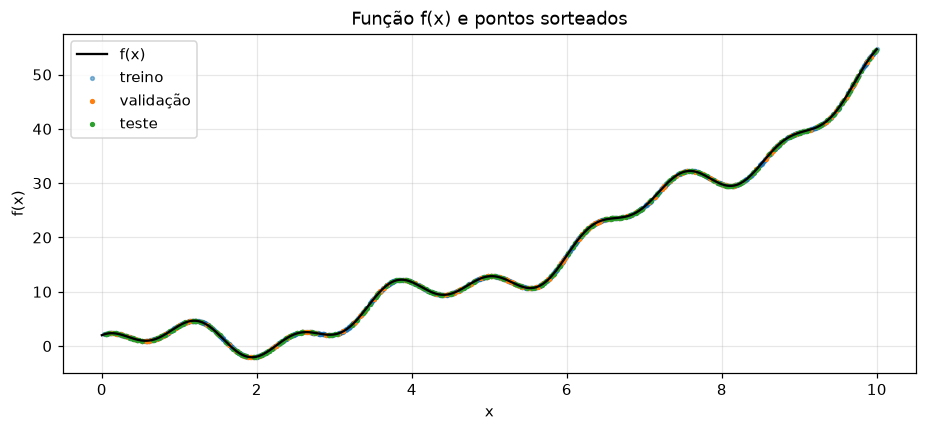

In [19]:
x_linha = np.linspace(0, 10, 1000).reshape(-1, 1)

plt.figure(figsize=(10, 4))
plt.plot(x_linha, f(x_linha), color="black", label="f(x)")
plt.scatter(x_treino, y_treino, s=6, alpha=0.5, label="treino")
plt.scatter(x_val, y_val, s=6, label="validação")
plt.scatter(x_teste, y_teste, s=6, label="teste")
plt.title("Função f(x) e pontos sorteados")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(PASTA_FIGURAS / "1a_dados.png", bbox_inches="tight")
plt.show()

O que observar:
- A função tem duas partes: uma parábola que cresce (o 0,5x²) e ondas por cima dela (o seno e o cosseno). A rede precisa aprender as duas coisas ao mesmo tempo.
- Os pontos de treino, validação e teste estão espalhados por todo o intervalo de 0 a 10. Então a rede vai ser testada em regiões que ela também viu no treino, só que em pontos diferentes.

## Criando a rede
Usamos 3 camadas escondidas com 128 neurônios cada e ativação Tanh. A Tanh é uma curva suave, o que combina com uma função suave como a f(x). Com ReLU a rede formaria pedaços de retas, e as ondas ficariam "quebradas".

In [20]:
fixar_semente()
modelo_a = MLP(entradas=1, camadas=[128, 128, 128], ativacao=nn.Tanh).to(device)
print(modelo_a)
print("Total de pesos treináveis:", sum(p.numel() for p in modelo_a.parameters()))

MLP(
  (rede): Sequential(
    (0): Linear(in_features=1, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): Tanh()
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)
Total de pesos treináveis: 33409


## Treinando
- Até 2000 épocas, taxa de aprendizado inicial de 0,003.
- A taxa de aprendizado é reduzida quando a validação para de melhorar.
- O treino para sozinho se a validação ficar 300 épocas sem melhorar.

In [21]:
historico_a = treinar(modelo_a, loader_treino, loader_val, epocas=2000, lr=3e-3,
                      paciencia=300, reduzir_lr=True, nome="Item a")

Item a:   0%|                                                                     | 0/2000 [00:00<?, ?época/s]

Item a:   1%|▎                 | 28/2000 [00:02<02:22, 13.80época/s, melhor=28, treino=1.07e-02, val=1.00e-02]

Item a:   3%|▌                 | 61/2000 [00:04<02:06, 15.36época/s, melhor=58, treino=6.38e-03, val=6.90e-03]

Item a:   5%|▊                 | 94/2000 [00:06<02:00, 15.85época/s, melhor=94, treino=1.65e-03, val=1.28e-03]

Item a:   6%|█               | 126/2000 [00:08<02:00, 15.58época/s, melhor=126, treino=3.47e-04, val=3.77e-04]

Item a:   8%|█▎              | 160/2000 [00:10<01:55, 15.94época/s, melhor=154, treino=2.95e-04, val=2.15e-04]

... (55 outputs left out)

Item a:  97%|█████████████▌| 1943/2000 [02:10<00:03, 14.80época/s, melhor=1886, treino=9.42e-07, val=8.79e-07]

Item a:  99%|█████████████▊| 1973/2000 [02:13<00:01, 14.30época/s, melhor=1973, treino=8.92e-07, val=8.12e-07]

Item a: 100%|██████████████| 2000/2000 [02:14<00:00, 14.82época/s, melhor=1991, treino=8.88e-07, val=8.27e-07]

Melhor época: 1991 (erro de validação = 7.85e-07)


## Curvas de erro de treino e de validação

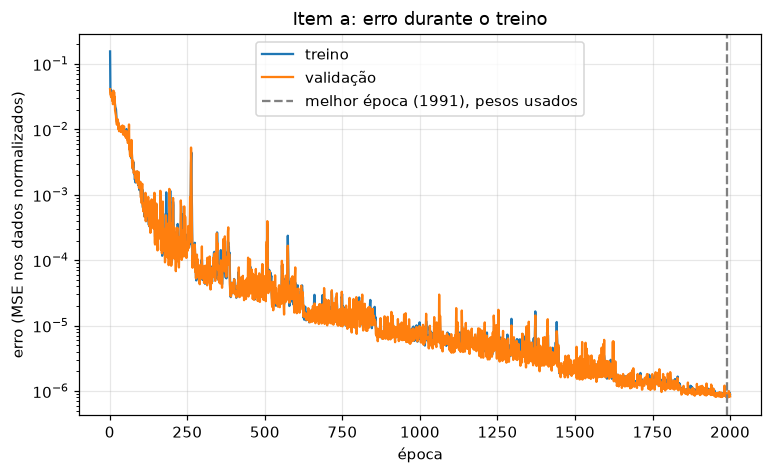

In [22]:
grafico_curvas(historico_a, "Item a: erro durante o treino", escala_log=True, arquivo="1a_curvas.png")

O que observar:
- O erro cai de cerca de 0,1 para menos de 0,000001 (o gráfico está em escala logarítmica, então cada linha de grade é 10 vezes menor que a anterior).
- As curvas de treino e de validação ficam praticamente uma em cima da outra durante todo o treino. Isso mostra que a rede não está decorando o treino: ela erra igual em pontos que nunca viu.
- Os picos que aparecem (por exemplo, perto da época 250) são momentos em que o passo de aprendizado foi grande demais. Com a redução automática da taxa de aprendizado eles vão ficando menores.
- A melhor época foi a 1991, quase no fim. O erro ainda estava caindo devagar, então com mais épocas daria para melhorar um pouco mais.

## Métricas no conjunto de teste
Valores na escala original de f(x).

In [23]:
y_previsto_teste = prever(modelo_a, x_teste, normalizador_x, normalizador_y)
metricas_a = calcular_metricas(y_teste, y_previsto_teste)
pd.DataFrame([metricas_a], index=["teste"]).round(5)

,MAE,MSE,RMSE,R²
teste,0.01141,0.00019,0.01384,1.0


## Função real e função aproximada
Aqui pedimos para a rede prever 1000 pontos igualmente espaçados entre 0 e 10 e desenhamos junto da função real. Embaixo mostramos o erro (real menos previsto) em cada ponto.

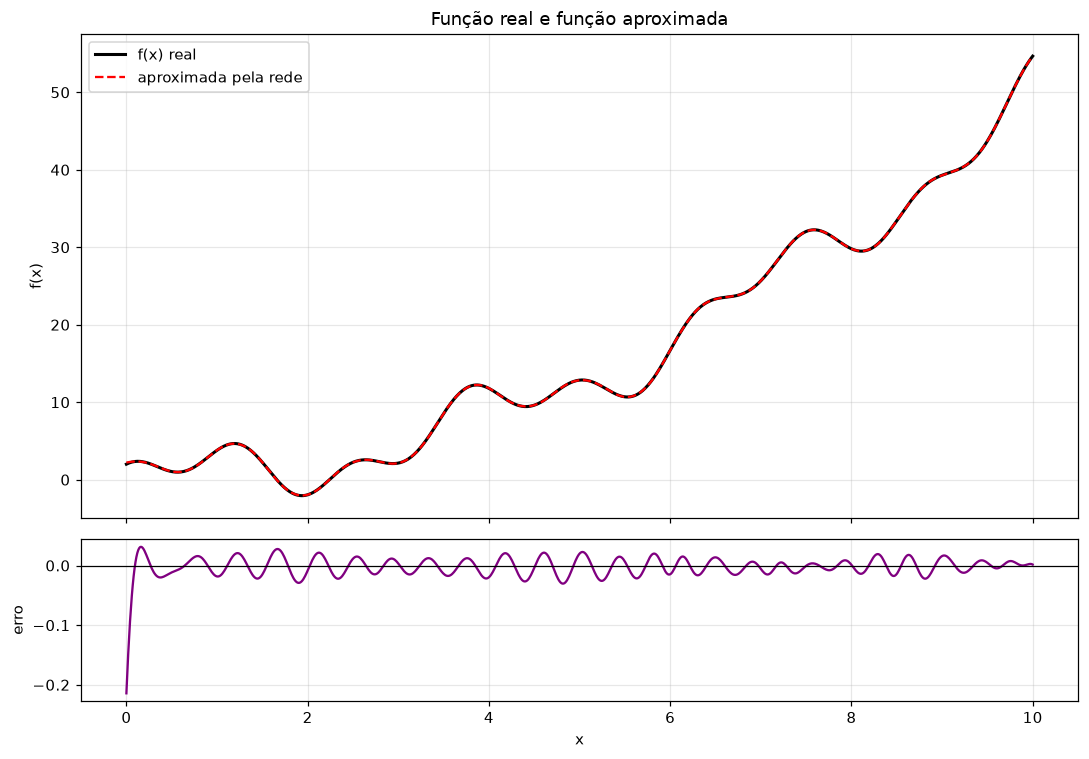

In [24]:
y_linha_previsto = prever(modelo_a, x_linha, normalizador_x, normalizador_y)
erro_linha = f(x_linha) - y_linha_previsto

fig, (cima, baixo) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
cima.plot(x_linha, f(x_linha), color="black", linewidth=2, label="f(x) real")
cima.plot(x_linha, y_linha_previsto, "r--", label="aproximada pela rede")
cima.set_ylabel("f(x)")
cima.set_title("Função real e função aproximada")
cima.legend()
cima.grid(alpha=0.3)
baixo.plot(x_linha, erro_linha, color="purple")
baixo.axhline(0, color="black", linewidth=0.8)
baixo.set_xlabel("x")
baixo.set_ylabel("erro")
baixo.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "1a_real_vs_aprox.png", bbox_inches="tight")
plt.show()

O que observar:
- A curva vermelha (rede) fica em cima da preta (real) em todo o intervalo de 0 a 10. Ela acompanha tanto a parábola quanto as ondas.
- No gráfico de baixo, o erro fica quase sempre entre -0,03 e +0,03. Para uma função que vai de -2 a 55, isso é muito pouco.
- O maior erro, de cerca de -0,2, aparece logo em x = 0. Na borda do intervalo só existem pontos de um lado, então a rede tem menos informação ali.

## Curvas real e predita no conjunto de teste
Agora só com os pontos de teste, que a rede nunca usou. À esquerda as duas curvas; à direita cada ponto é um exemplo de teste, com o valor real no eixo x e o previsto no eixo y. Se a rede acertasse tudo, todos os pontos ficariam em cima da linha tracejada.

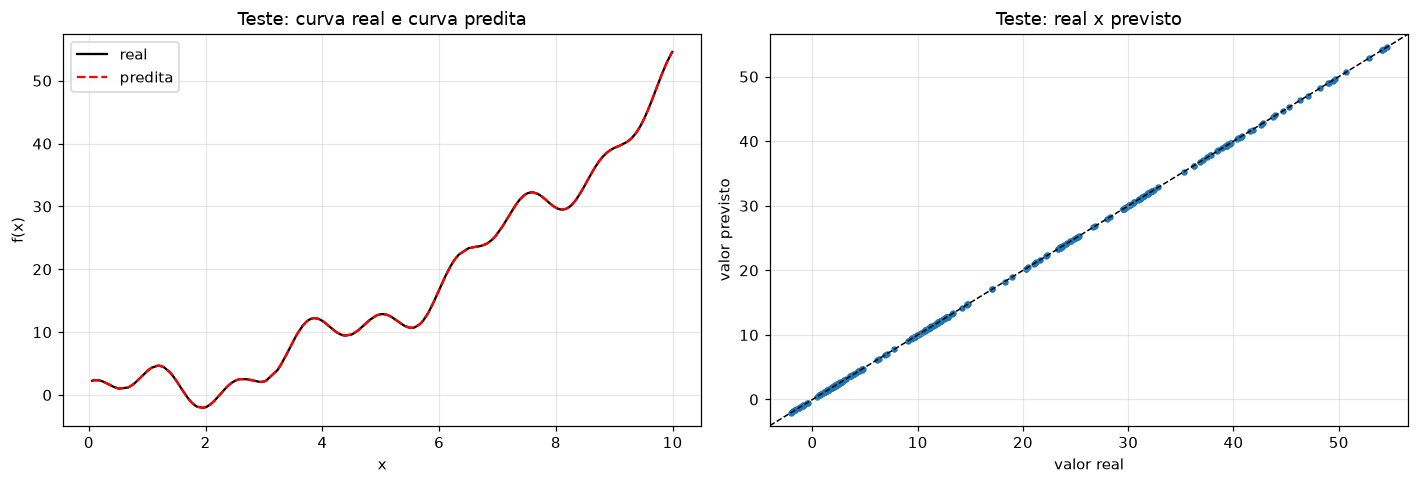

In [25]:
ordem = np.argsort(x_teste[:, 0])
limites = [y_teste.min() - 2, y_teste.max() + 2]

fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(13, 4.5))
esquerda.plot(x_teste[ordem], y_teste[ordem], color="black", label="real")
esquerda.plot(x_teste[ordem], y_previsto_teste[ordem], "r--", label="predita")
esquerda.set_xlabel("x")
esquerda.set_ylabel("f(x)")
esquerda.set_title("Teste: curva real e curva predita")
esquerda.legend()
esquerda.grid(alpha=0.3)
direita.scatter(y_teste, y_previsto_teste, s=10)
direita.plot(limites, limites, "k--", linewidth=1)
direita.set_xlim(limites)
direita.set_ylim(limites)
direita.set_xlabel("valor real")
direita.set_ylabel("valor previsto")
direita.set_title("Teste: real x previsto")
direita.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "1a_teste_real_vs_pred.png", bbox_inches="tight")
plt.show()

O que observar:
- À esquerda, a curva predita nos pontos de teste é igual à curva real.
- À direita, todos os pontos estão em cima da linha tracejada. Não existe nenhuma faixa de valores (baixos ou altos) em que a rede erre mais.

## Verificando overfitting

In [26]:
conjuntos_a = {"treino": (x_treino, y_treino), "validação": (x_val, y_val), "teste": (x_teste, y_teste)}
tabela_overfitting(modelo_a, conjuntos_a, normalizador_x, normalizador_y).round(5)

,MAE,MSE,RMSE,R²
treino,0.01091,0.00019,0.01362,1.0
validação,0.01115,0.00017,0.01316,1.0
teste,0.01141,0.00019,0.01384,1.0


Os erros em treino, validação e teste são praticamente iguais (RMSE de 0,0136, 0,0132 e 0,0138). Então não há overfitting no item a.

Isso faz sentido: os dados não têm ruído e os três conjuntos cobrem o mesmo intervalo de 0 a 10, então aprender bem o treino é o mesmo que aprender bem a função.

Um cuidado: a rede só aprendeu a função entre 0 e 10. Se pedirmos f(12), por exemplo, ela vai errar bastante, porque nunca viu nada fora desse intervalo.

---
# Item b: base Diabetes

## Carregando a base
Carregamos a versão sem normalização (`scaled=False`), para ver os valores nas unidades reais. A versão padrão do scikit-learn já vem normalizada.

In [27]:
diabetes = load_diabetes(as_frame=True, scaled=False)
tabela = diabetes.frame
tabela.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


São 442 pacientes e 10 atributos:
- age: idade
- sex: sexo (1 ou 2)
- bmi: índice de massa corporal (IMC)
- bp: pressão arterial média
- s1: colesterol total
- s2: LDL (colesterol "ruim")
- s3: HDL (colesterol "bom")
- s4: razão entre colesterol total e HDL
- s5: logaritmo dos triglicerídeos
- s6: glicose

A coluna target é o que queremos prever: uma medida de quanto a doença avançou um ano depois.

## Análise exploratória
### Valores ausentes e linhas repetidas

In [28]:
print("Tamanho da tabela:", tabela.shape)
print("Valores ausentes:", tabela.isna().sum().sum())
print("Linhas repetidas:", tabela.duplicated().sum())

Tamanho da tabela: (442, 11)
Valores ausentes: 0
Linhas repetidas: 0


A base está completa: não tem nenhum valor faltando nem linha repetida. Então não precisamos preencher nem remover nada.

### Estatísticas de cada coluna

In [29]:
tabela.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


As colunas estão em escalas bem diferentes. A idade vai de 19 a 79, o colesterol total (s1) vai de 97 a 301, e o s5 fica entre 3 e 6. Se a rede receber os dados assim, as colunas com números maiores dominam o aprendizado. Por isso vamos normalizar.

### Distribuição de cada coluna

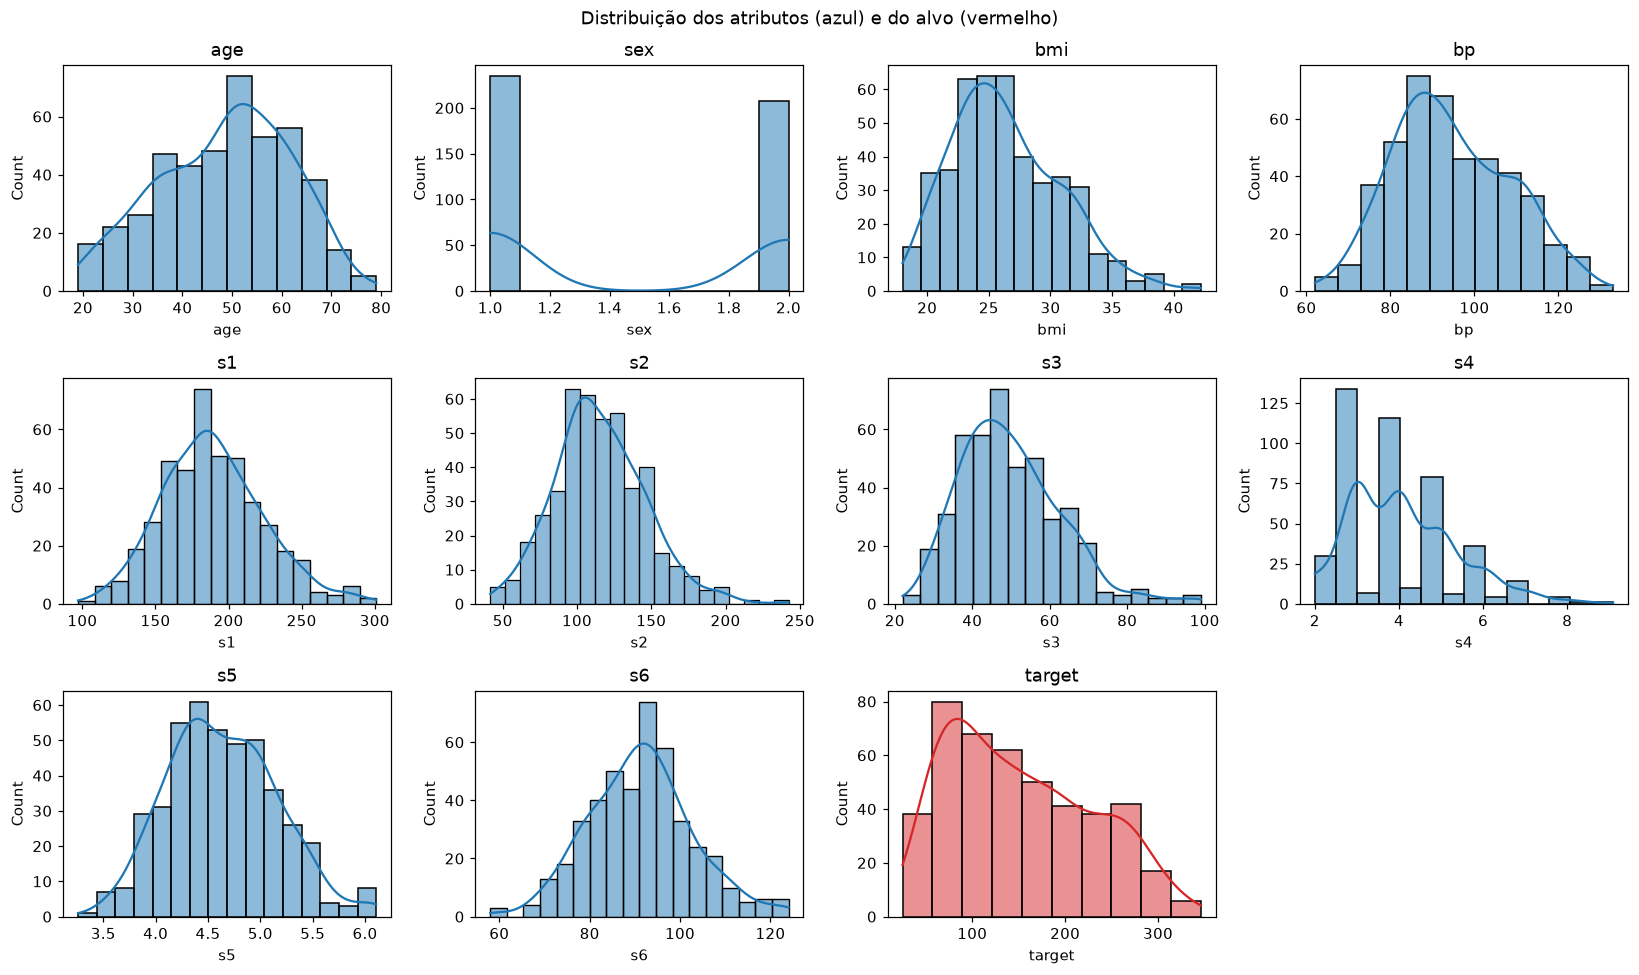

In [30]:
fig, eixos = plt.subplots(3, 4, figsize=(15, 9))
for eixo, coluna in zip(eixos.flat, tabela.columns):
    cor = "tab:red" if coluna == "target" else "tab:blue"
    sns.histplot(tabela[coluna], kde=True, ax=eixo, color=cor)
    eixo.set_title(coluna)
for eixo in eixos.flat[len(tabela.columns):]:
    eixo.axis("off")
plt.suptitle("Distribuição dos atributos (azul) e do alvo (vermelho)")
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "1b_histogramas.png", bbox_inches="tight")
plt.show()

O que observar:
- age, bmi, bp, s1, s2, s3, s5 e s6 têm formato parecido com um sino. bmi e s3 têm uma "cauda" para a direita, com alguns pacientes de valores bem altos.
- sex só tem dois valores (1 e 2), com quantidades parecidas de pacientes em cada um.
- s4 só tem alguns valores quebrados (2, 3, 4, 5...), porque é uma razão arredondada.
- O alvo (target) tem mais pacientes com valores baixos, entre 50 e 150, e vai diminuindo até 346.

### Correlação entre as colunas
A correlação vai de -1 a 1. Perto de 1: as duas colunas sobem juntas. Perto de -1: quando uma sobe, a outra desce. Perto de 0: não tem relação linear.

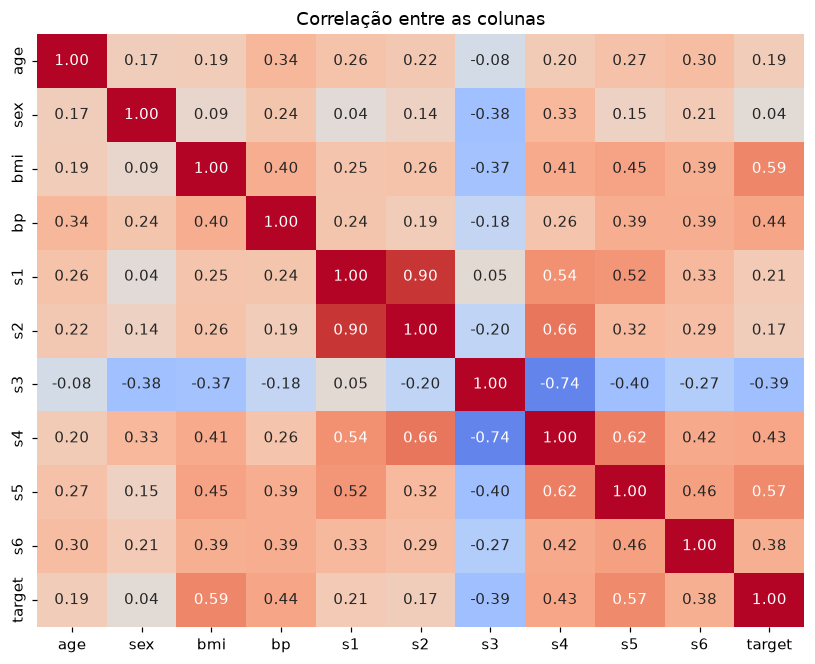

In [31]:
correlacao = tabela.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar=False)
plt.title("Correlação entre as colunas")
plt.savefig(PASTA_FIGURAS / "1b_correlacao.png", bbox_inches="tight")
plt.show()

O que observar:
- Os atributos que mais se relacionam com o alvo são bmi (0,59), s5 (0,57), bp (0,44) e s4 (0,43). s3 tem relação negativa (-0,39): quanto mais HDL, o colesterol bom, menor a progressão.
- sex (0,04) e s2 (0,17) quase não têm relação direta com o alvo.
- s1 e s2 têm correlação de 0,90, ou seja, carregam quase a mesma informação. s3 e s4 também andam juntos (-0,74). Isso é redundância. Como são só 10 atributos e a rede tem proteções contra overfitting, decidimos manter todos.

### Relação dos atributos mais importantes com o alvo

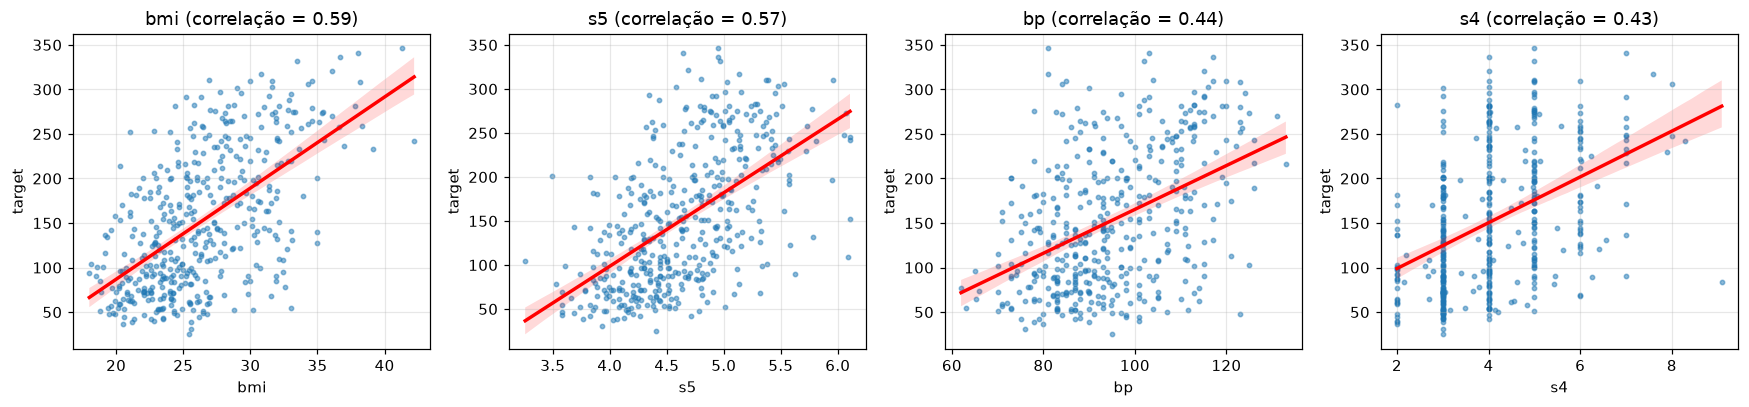

In [32]:
mais_importantes = correlacao["target"].drop("target").abs().sort_values(ascending=False).index[:4]

fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8))
for eixo, coluna in zip(eixos, mais_importantes):
    sns.regplot(data=tabela, x=coluna, y="target", ax=eixo,
                scatter_kws={"s": 8, "alpha": 0.5}, line_kws={"color": "red"})
    eixo.set_title(f"{coluna} (correlação = {correlacao.loc[coluna, 'target']:.2f})")
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "1b_dispersao.png", bbox_inches="tight")
plt.show()

O que observar:
- Nos quatro gráficos a linha vermelha sobe: quanto maior o atributo, maior tende a ser a progressão.
- Mas os pontos estão muito espalhados em volta da linha. Pacientes com o mesmo IMC, por exemplo, têm progressões que vão de 50 a 300. Então nenhum atributo sozinho consegue prever bem o alvo, e já dá para esperar que o erro final não vai ser pequeno.

## Separando entradas e saída

In [33]:
X = tabela.drop(columns="target").values
y = tabela[["target"]].values
print("Entradas:", X.shape)
print("Saída:", y.shape)

Entradas: (442, 10)
Saída: (442, 1)


## Dividindo em treino, validação e teste

In [34]:
X_treino, X_val, X_teste, y_treino, y_val, y_teste = dividir_dados(X, y)
print("Treino:", len(X_treino))
print("Validação:", len(X_val))
print("Teste:", len(X_teste))

Treino: 309
Validação: 66
Teste: 67


## Normalizando
Mesma ideia do item a: média 0 e desvio 1, calculados só com o treino. Normalizamos as entradas e também o alvo.

In [35]:
normalizador_X = StandardScaler().fit(X_treino)
normalizador_y = StandardScaler().fit(y_treino)

X_treino_n = normalizador_X.transform(X_treino)
X_val_n = normalizador_X.transform(X_val)
y_treino_n = normalizador_y.transform(y_treino)
y_val_n = normalizador_y.transform(y_val)

## Criando os loaders

In [36]:
loader_treino = criar_loader(X_treino_n, y_treino_n, tamanho_lote=32, embaralhar=True)
loader_val = criar_loader(X_val_n, y_val_n, tamanho_lote=256, embaralhar=False)

## Criando a rede
A base é pequena: só 309 pacientes no treino. Uma rede grande decoraria esses pacientes. Por isso usamos uma rede pequena:
- entrada com 10 atributos;
- camada escondida com 32 neurônios, ReLU e dropout de 20%;
- camada escondida com 16 neurônios, ReLU e dropout de 20%;
- saída com 1 neurônio (a progressão prevista).

In [37]:
modelo_b = criar_modelo_b()
print(modelo_b)
print("Total de pesos treináveis:", sum(p.numel() for p in modelo_b.parameters()))

MLP(
  (rede): Sequential(
    (0): Linear(in_features=10, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)
Total de pesos treináveis: 897


## Treinando
Além do dropout, usamos weight decay, que penaliza pesos muito grandes e também ajuda contra overfitting. O treino para se a validação ficar 100 épocas sem melhorar.

In [38]:
historico_b = treinar_modelo_b(modelo_b, loader_treino, loader_val)

Item b:   0%|                                                                     | 0/1500 [00:00<?, ?época/s]

Item b:   4%|▊                 | 66/1500 [00:02<00:43, 32.70época/s, melhor=21, treino=4.47e-01, val=4.18e-01]

Item b:   4%|▊                 | 66/1500 [00:03<01:17, 18.59época/s, melhor=21, treino=3.92e-01, val=4.30e-01]

Parou na época 121: a validação ficou 100 épocas sem melhorar.
Melhor época: 21 (erro de validação = 3.98e-01)


## Curvas de erro de treino e de validação

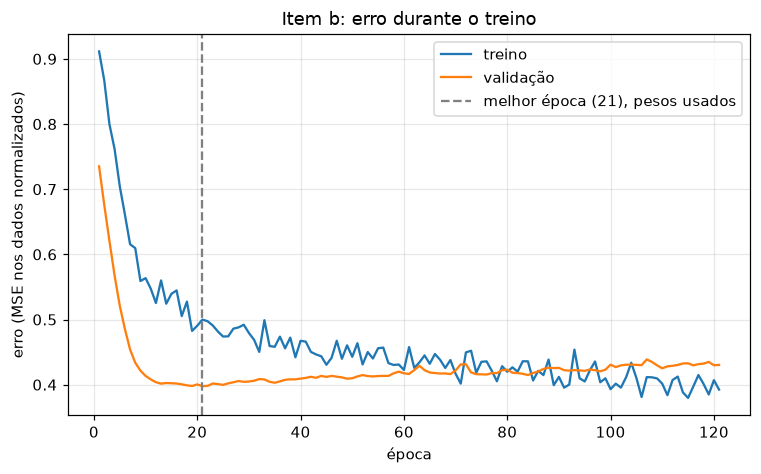

In [39]:
grafico_curvas(historico_b, "Item b: erro durante o treino", arquivo="1b_curvas.png")

O que observar:
- A validação atinge o menor erro bem cedo, na época 21. Depois disso ela sobe devagar, sinal de que a rede começaria a decorar o treino. O early stopping parou o treino na época 121 e voltou para os pesos da época 21.
- A curva de validação fica abaixo da de treino. Parece estranho, mas é efeito do dropout: no treino, 20% dos neurônios são desligados, o que aumenta o erro de treino. Na validação a rede usa todos os neurônios.
- A curva de treino é mais "tremida" pelo mesmo motivo: a cada lote, neurônios diferentes são desligados.

## Métricas no conjunto de teste
Para saber se o resultado é bom, comparamos com uma regressão linear simples, que é o modelo mais básico para esse tipo de problema.

In [40]:
y_previsto_mlp = prever(modelo_b, X_teste, normalizador_X, normalizador_y)

regressao_linear = LinearRegression().fit(X_treino_n, y_treino)
y_previsto_linear = regressao_linear.predict(normalizador_X.transform(X_teste))

pd.DataFrame({
    "MLP": calcular_metricas(y_teste, y_previsto_mlp),
    "Regressão linear": calcular_metricas(y_teste, y_previsto_linear),
}).T.round(2)

,MAE,MSE,RMSE,R²
MLP,45.98,3130.51,55.95,0.45
Regressão linear,45.57,3139.37,56.03,0.45


## Valores reais e preditos

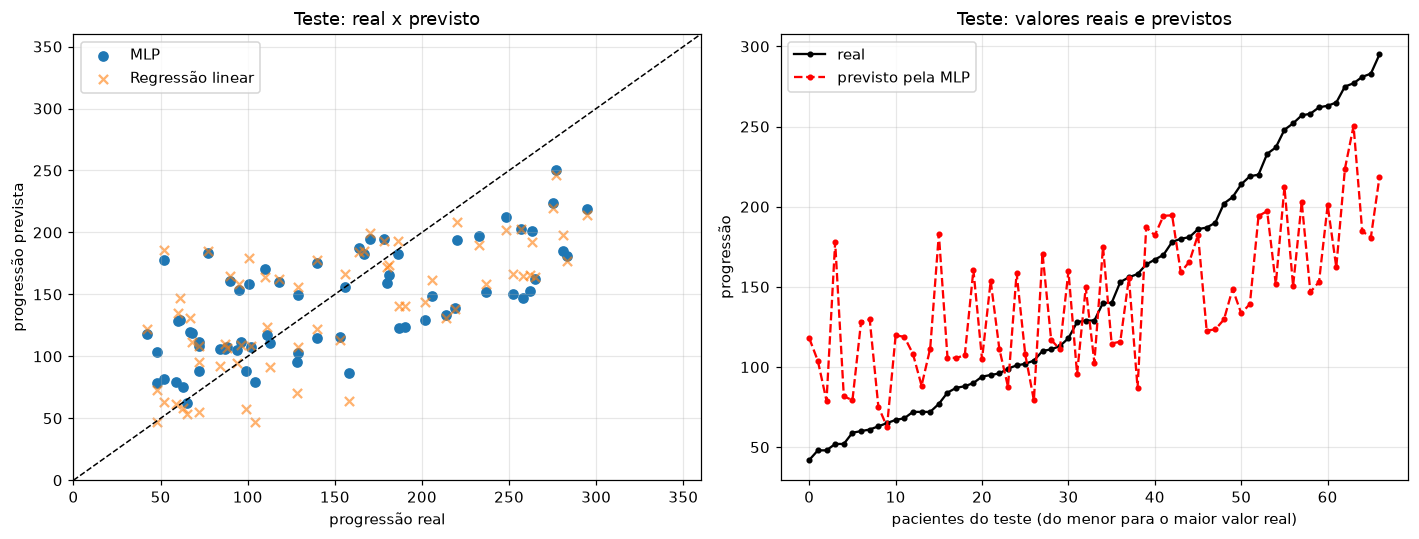

In [41]:
ordem = np.argsort(y_teste[:, 0])

fig, (esquerda, direita) = plt.subplots(1, 2, figsize=(13, 5))
esquerda.scatter(y_teste, y_previsto_mlp, label="MLP")
esquerda.scatter(y_teste, y_previsto_linear, marker="x", alpha=0.6, label="Regressão linear")
esquerda.plot([0, 360], [0, 360], "k--", linewidth=1)
esquerda.set_xlim(0, 360)
esquerda.set_ylim(0, 360)
esquerda.set_xlabel("progressão real")
esquerda.set_ylabel("progressão prevista")
esquerda.set_title("Teste: real x previsto")
esquerda.legend()
esquerda.grid(alpha=0.3)
direita.plot(y_teste[ordem], "ko-", markersize=3, label="real")
direita.plot(y_previsto_mlp[ordem], "r.--", label="previsto pela MLP")
direita.set_xlabel("pacientes do teste (do menor para o maior valor real)")
direita.set_ylabel("progressão")
direita.set_title("Teste: valores reais e previstos")
direita.legend()
direita.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PASTA_FIGURAS / "1b_real_vs_pred.png", bbox_inches="tight")
plt.show()

O que observar:
- Os pontos da MLP (azul) e da regressão linear (laranja) ficam quase nos mesmos lugares. As duas fazem previsões muito parecidas.
- Os pontos formam uma nuvem "deitada" em relação à linha tracejada: para pacientes com progressão baixa a rede prevê um pouco mais alto, e para progressão alta prevê mais baixo. A rede puxa as previsões para perto da média (cerca de 150), porque os atributos não têm informação suficiente para separar bem os casos extremos.
- À direita dá para ver isso de novo: a linha vermelha sobe junto com a preta, mas com bastante oscilação e sem chegar aos valores mais altos.

## Verificando overfitting
### Métricas em treino, validação e teste

In [42]:
conjuntos_b = {"treino": (X_treino, y_treino), "validação": (X_val, y_val), "teste": (X_teste, y_teste)}
tabela_overfitting(modelo_b, conjuntos_b, normalizador_X, normalizador_y).round(2)

,MAE,MSE,RMSE,R²
treino,43.15,2772.24,52.65,0.55
validação,37.40,2445.75,49.45,0.52
teste,45.98,3130.51,55.95,0.45


O RMSE fica em 52,7 no treino, 49,5 na validação e 56,0 no teste. A diferença entre treino e teste é pequena (cerca de 3 pontos), então a rede não decorou o treino.

A rede tem 897 pesos e o treino tem 309 pacientes. Mesmo assim, com dropout, weight decay e early stopping, ela ficou com um erro de treino parecido com o de dados novos.

### Como seria uma rede com overfitting
Para mostrar que o dropout, o weight decay e o early stopping estão fazendo diferença, treinamos uma rede maior (128, 64 e 32 neurônios) sem nenhuma dessas proteções, por 1000 épocas, e ficamos com os pesos da última época.

In [43]:
fixar_semente()
modelo_sem_protecao = MLP(entradas=10, camadas=[128, 64, 32], ativacao=nn.ReLU).to(device)
historico_sem_protecao = treinar(modelo_sem_protecao, loader_treino, loader_val, epocas=1000, lr=1e-3,
                                 voltar_melhor=False, nome="Sem proteção")

Sem proteção:   0%|                                                               | 0/1000 [00:00<?, ?época/s]

Sem proteção:   6%|▊            | 60/1000 [00:02<00:31, 29.48época/s, melhor=4, treino=8.04e-02, val=6.49e-01]

Sem proteção:  13%|█▌          | 127/1000 [00:04<00:27, 31.67época/s, melhor=4, treino=7.26e-03, val=7.18e-01]

Sem proteção:  21%|██▌         | 213/1000 [00:06<00:21, 36.64época/s, melhor=4, treino=2.24e-03, val=7.19e-01]

Sem proteção:  29%|███▌        | 294/1000 [00:08<00:18, 38.00época/s, melhor=4, treino=2.83e-03, val=6.84e-01]

Sem proteção:  38%|████▌       | 375/1000 [00:10<00:16, 38.84época/s, melhor=4, treino=6.87e-04, val=6.79e-01]

... (5 outputs left out)

Sem proteção:  89%|██████████▋ | 887/1000 [00:22<00:02, 41.63época/s, melhor=4, treino=1.20e-06, val=6.52e-01]

Sem proteção:  97%|███████████▋| 971/1000 [00:24<00:00, 41.67época/s, melhor=4, treino=5.27e-05, val=6.36e-01]

Sem proteção: 100%|███████████| 1000/1000 [00:24<00:00, 40.07época/s, melhor=4, treino=4.80e-06, val=6.36e-01]

Melhor época: 4 (erro de validação = 3.82e-01)


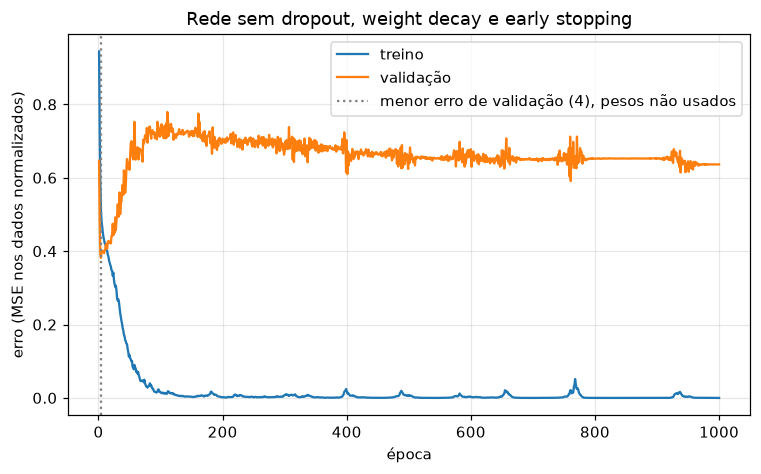

In [44]:
grafico_curvas(historico_sem_protecao, "Rede sem dropout, weight decay e early stopping", arquivo="1b_curvas_overfitting.png")

Este é o overfitting clássico:
- O erro de treino cai até quase zero: a rede decorou a progressão de cada um dos 309 pacientes.
- O erro de validação, ao contrário, atinge o menor valor (0,38) na época 4, depois sobe para cerca de 0,65 e fica lá.
- A linha pontilhada mostra que a melhor época foi a 4, mas essa rede usa os pesos da época 1000.

In [45]:
tabela_overfitting(modelo_sem_protecao, conjuntos_b, normalizador_X, normalizador_y).round(2)

,MAE,MSE,RMSE,R²
treino,0.14,0.03,0.17,1.00
validação,47.15,3913.32,62.56,0.23
teste,50.93,5094.86,71.38,0.10


Nos números, o RMSE de treino é só 0,17, mas no teste ele vai para 71,4 (contra 56,0 da nossa rede) e o R² cai para 0,10. Ou seja, a rede ficou pior que a nossa justamente nos pacientes que nunca viu.

Isso mostra que as proteções que usamos (rede menor, dropout, weight decay e early stopping) estão fazendo diferença.

### Validação cruzada
O teste tem só 67 pacientes, então o resultado depende muito de quais pacientes caíram nele. Para ter um número mais confiável, repetimos tudo 5 vezes, cada vez usando um pedaço diferente da base como teste (validação cruzada com 5 partes).

In [46]:
lista_resultados = []
partes = KFold(n_splits=5, shuffle=True, random_state=0)

for numero_parte, (indices_treino, indices_teste) in enumerate(partes.split(X), start=1):
    lista_resultados += avaliar_parte(X[indices_treino], y[indices_treino],
                                      X[indices_teste], y[indices_teste], numero_parte)

Parte 1:   0%|                                                                    | 0/1500 [00:00<?, ?época/s]

Parte 1:   5%|▊                | 71/1500 [00:02<00:40, 35.43época/s, melhor=18, treino=3.76e-01, val=4.42e-01]

Parte 1:   5%|▊                | 71/1500 [00:03<01:01, 23.20época/s, melhor=18, treino=3.60e-01, val=4.62e-01]

Parou na época 118: a validação ficou 100 épocas sem melhorar.
Melhor época: 18 (erro de validação = 4.05e-01)


Parte 2:   0%|                                                                    | 0/1500 [00:00<?, ?época/s]

Parte 2:   5%|▉                | 81/1500 [00:02<00:35, 40.36época/s, melhor=16, treino=3.89e-01, val=4.31e-01]

... (13 outputs left out)

Parte 5:   0%|                                                                    | 0/1500 [00:00<?, ?época/s]

Parte 5:   6%|▉                | 87/1500 [00:02<00:32, 43.31época/s, melhor=10, treino=4.56e-01, val=5.68e-01]

Parte 5:   6%|▉                | 87/1500 [00:02<00:40, 35.01época/s, melhor=10, treino=3.94e-01, val=5.73e-01]

Parou na época 110: a validação ficou 100 épocas sem melhorar.
Melhor época: 10 (erro de validação = 4.87e-01)


In [47]:
tabela_resultados = pd.DataFrame(lista_resultados)
tabela_resultados.groupby("modelo")[["MAE", "MSE", "RMSE", "R²"]].agg(["mean", "std"]).round(2)

MAE            MSE           RMSE          R²     
                   mean   std     mean     std   mean   std  mean  std
modelo                                                                
MLP               44.84  1.14  3044.53  320.13  55.12  2.90  0.48  0.1
Regressão linear  44.65  1.54  3016.39  248.73  54.89  2.21  0.48  0.1

Nas 5 repetições a MLP teve RMSE médio de 55,1 (variando 2,9 para mais ou para menos) e a regressão linear teve 54,9 (variando 2,2). As duas têm R² de 0,48.

A diferença entre elas é menor que a variação entre as repetições. Então, na prática, a MLP e a regressão linear empatam nesta base.

---
# Conclusão

Item a
- A MLP aprendeu a função f(x) com RMSE de 0,014 no teste. As curvas real e aproximada ficam uma em cima da outra.
- Não houve overfitting: treino, validação e teste têm o mesmo erro.

Item b
- A MLP teve RMSE de 56,0 e MAE de 46,0 no teste (R² de 0,45). Em média, a previsão erra cerca de 46 pontos numa escala que vai de 25 a 346.
- Esse resultado é igual ao de uma regressão linear. A relação entre os atributos e a progressão é quase linear e tem muito ruído, porque a doença depende de muitos fatores que não estão nesses 10 atributos. Com só 442 pacientes não há o que a rede aprender além do que a regressão linear já pega.
- O experimento sem proteção mostrou que uma rede maior decora os pacientes de treino e piora no teste (RMSE de 71,4). Por isso usamos uma rede pequena com dropout, weight decay e early stopping.
- Para melhorar de verdade seria preciso ter mais pacientes ou mais informações sobre eles, e não uma rede maior.